# Score-CAM Visualization

This notebook implements **Score-CAM (Score-Weighted Class Activation Mapping)** for visualizing the regions of an image that contribute most to the model's prediction.

The notebook performs the following steps:

- Load a trained TrashNet model
- Load an input waste image
- Generate a Score-CAM heatmap
- Overlay the heatmap on the original image
- Display and save the visualization

This experiment supports **Objective 5** by verifying that the model focuses on meaningful waste features instead of background artifacts.

> **Note:** `ScoreCAM` and `overlay_heatmap` now live in `scorecam.py` (a shared module, alongside `dataset.py` and `models.py`) so they can also be imported directly by `classify_tool.ipynb`.

In [3]:
import os

import torch

from PIL import Image

import matplotlib.pyplot as plt

import config

from dataset import get_clean_transforms
from models import build_model
from scorecam import ScoreCAM, overlay_heatmap

In [9]:
BACKBONE = "resnet50"

# Example image path
IMAGE_PATH = "data/trashnet/plastic/plastic1.jpg"

# Optional output file
OUTPUT_PATH = None

In [10]:
device = config.DEVICE

checkpoint = os.path.join(
    config.CHECKPOINT_DIR,
    f"{BACKBONE}_trashnet_best.pt"
)

model, target_layer = build_model(
    BACKBONE,
    len(config.TRASHNET_CLASSES),
    pretrained=False
)

model.load_state_dict(
    torch.load(
        checkpoint,
        map_location=device
    )
)

<All keys matched successfully>

In [11]:
_, transform = get_clean_transforms()

image = Image.open(
IMAGE_PATH
).convert("RGB")

input_tensor = transform(
image
).unsqueeze(0)

In [12]:
scorecam = ScoreCAM(
model,
target_layer,
device
)

cam, class_index = scorecam.generate(
input_tensor
)

predicted_label = config.TRASHNET_CLASSES[
class_index
]

print("Prediction :", predicted_label)

Prediction : glass


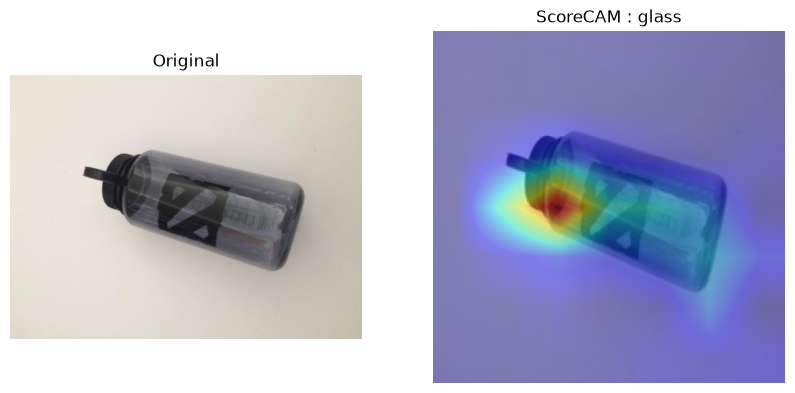

In [13]:
overlay = overlay_heatmap(
image.resize(
    (config.IMG_SIZE, config.IMG_SIZE)
),
cam
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)

plt.imshow(image)

plt.title("Original")

plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(overlay)

plt.title(f"ScoreCAM : {predicted_label}")

plt.axis("off")

plt.show()

In [14]:
if OUTPUT_PATH is None:

    OUTPUT_PATH = os.path.join(
        config.RESULTS_DIR,
        f"scorecam_{BACKBONE}.png"
    )

plt.imsave(
    OUTPUT_PATH,
    overlay
)

print("Saved to")

print(OUTPUT_PATH)

Saved to
e:\wasteClassificationProject_FIXED\wasteClassificationProject\outputs\scorecam_resnet50.png


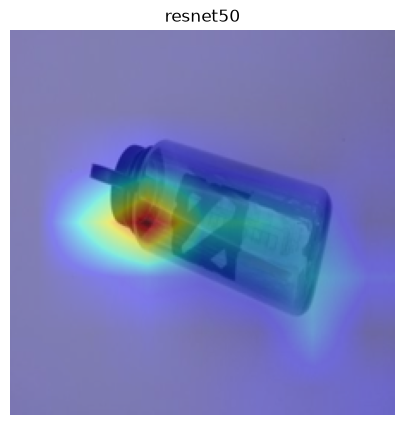

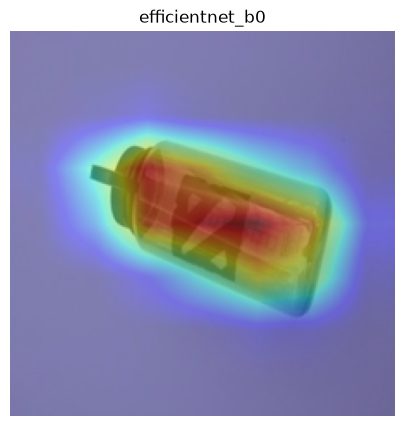

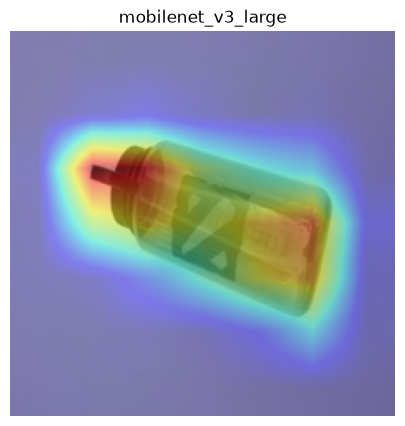

In [15]:
for backbone in config.BACKBONES:

    model, target = build_model(
        backbone,
        len(config.TRASHNET_CLASSES),
        pretrained=False
    )

    checkpoint = os.path.join(
        config.CHECKPOINT_DIR,
        f"{backbone}_trashnet_best.pt"
    )

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location=device
        )
    )

    scorecam = ScoreCAM(
        model,
        target,
        device
    )

    cam, idx = scorecam.generate(
        input_tensor
    )

    overlay = overlay_heatmap(
        image.resize(
            (config.IMG_SIZE, config.IMG_SIZE)
        ),
        cam
    )

    plt.figure(figsize=(5,5))

    plt.imshow(overlay)

    plt.title(backbone)

    plt.axis("off")

    plt.show()